# Figure 3 — sparseness

Panels (a)-(d) of Section 3. Conventions follow notebook 04.

In [35]:
# ---------------------------------------------------------------- CONFIG
# Same conventions as 04_fig2_spectrum_by_state: 1 s bins, the high-rate
# minority excluded by the rule in cell 3, PCs 3-50 for every fit.
import os, sys, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, os.getcwd())
from utils.population_metrics import compute_sparseness

DATA_DIR = "/Users/ilgaz/Desktop/data_share_20260429/data"
# Single source of data: the local pack of 1 s binned matrices built from the
# DANDI archive (scripts/crawl_buzsaki.py, stage "extract"). The laboratory
# session files read by earlier versions are no longer used here.
FIG_DIR  = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

BIN_SIZE   = 1.0                 # s
STATES     = ["Wake", "NREM", "REM"]
MAIN_RANGE = (3, 50)             # PC range for every exponent here
BIN_WIDTHS = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0]   # panel (d) sweep
WINDOW     = 2000                # bins per window in panel (d); above the
                                 # ~2000-bin floor where alpha stabilises
N_SUB      = None                # neurons kept per session in panel (c);
                                 # set in that cell to the smallest retained
                                 # count of the four sessions
N_SUB_DRAWS = 20
SEED       = 1
COLORS     = {"Wake": "#D55E00", "NREM": "#0072B2", "REM": "#009E73", "pooled": "#555555"}
SESS_COLORS = {"Achilles": "#555555", "Cicero": "#CC79A7", "Buddy": "#E69F00", "BWRat18": "#56B4E9"}


In [ ]:
# -------------------------------------------------- data, epochs, masks
# Source switched to the public archive copy (DANDI 000044) so this session is
# binned and scored exactly as the multi-session set of notebook 06. The
# archive conversion carries three states where the laboratory sessInfo file
# carries five: its waking category absorbs the drowsy and intermediate
# periods and the maze epoch, so Wake here is a broader category (16,747 s
# against the 5,698 s scored Wake by the laboratory). Spike times are
# identical between the two copies; only the state annotation differs.
PACK = DATA_DIR + "/dandi_binned_1s_rat.npz"
TAG  = "000044_sub-Achilles_ses-Achilles-10252013"

_z = np.load(PACK, allow_pickle=True)
X = _z[f"X__{TAG}"].astype(float)               # bins x neurons, 1 s bins
_lab = _z[f"state__{TAG}"].copy()
_lab[_lab == "Quiet"] = "Wake"                  # same mapping as dandi_data.load_pack
neuron_ids    = np.arange(X.shape[1])
sess_duration = X.shape[0] * BIN_SIZE
edges         = np.arange(X.shape[0] + 1) * BIN_SIZE
centres       = edges[:-1] + BIN_SIZE / 2

masks = {s: (_lab == s) for s in STATES}
masks["pooled"] = masks["Wake"] | masks["NREM"] | masks["REM"]

print("session", round(sess_duration, 1), "s |", X.shape[0], "bins x", X.shape[1], "neurons")
print("bins per state:", {k: int(v.sum()) for k, v in masks.items()},
      "| unscored:", int((~np.isin(_lab, STATES)).sum()))


In [37]:
# ------------------------------- exclusion rule, applied to any session
# Cut at the largest step in the rank-ordered log rate (same rule as
# notebook 04). Returned as a function so the other sessions get it too.
def retained(Xs, duration):
    rate  = Xs.sum(0) / duration
    order = np.argsort(-np.log(np.maximum(rate, 1e-12)))
    gap   = -np.diff(np.log(np.maximum(rate, 1e-12))[order])
    n_ex  = int(np.argmax(gap[:40])) + 1
    return np.setdiff1d(np.arange(Xs.shape[1]), order[:n_ex]), n_ex

keep, n_ex = retained(X, sess_duration)
Xk = X[:, keep]
assert n_ex == 15 and Xk.shape[1] == 122, (n_ex, Xk.shape)

s_t, s_n = compute_sparseness(Xk)      # active fraction per bin, per neuron
# The rule above needs the population to be large; on a 40-neuron session
# the largest gap can fall anywhere. The other sessions therefore inherit
# Achilles' cut as a rate threshold, which is the same criterion stated in
# Hz instead of in ranks.
rate_all = X.sum(0) / sess_duration
THRESH = float(np.sort(rate_all)[::-1][n_ex - 1])
print("cut at", round(THRESH, 2), "Hz")

print("122 neurons |  mean active fraction over the whole session:", round(float(s_t.mean()), 4))
print("per state:", {s: round(float(s_t[masks[s]].mean()), 4) for s in STATES})


cut at 4.71 Hz
122 neurons |  mean active fraction over the whole session: 0.2646
per state: {'Wake': 0.2533, 'NREM': 0.304, 'REM': 0.2233}


### Panel (a) — participation per neuron, all 137 units


main mode: max a_i 0.682 | removed cluster: min a_i 0.815 | median 0.241 | mean 0.336


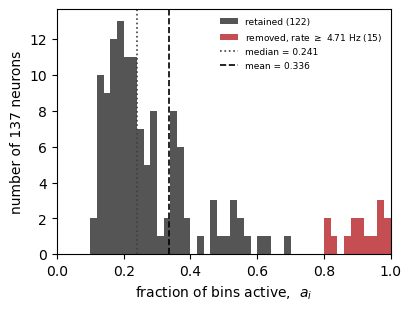

In [38]:
# ------------------------------------------- (a) participation per neuron
# Neuron-side marginal of the same binary matrix, on all 137 units: its
# bimodality is what justifies the exclusion applied in the cell above.
_, a_i = compute_sparseness(X)
excl   = np.setdiff1d(np.arange(X.shape[1]), keep)
bins_p = np.arange(0, 1.02, 0.02)
fig, ax = plt.subplots(figsize=(4.0, 3.0), constrained_layout=True)
ax.hist(a_i[keep], bins=bins_p, color="#555555", label=f"retained ({len(keep)})")
ax.hist(a_i[excl], bins=bins_p, color="#c44e52", label=f"removed, rate $\\geq$ {THRESH:.2f} Hz ({n_ex})")
ax.axvline(float(np.median(a_i)), ls=":",  c="0.25", lw=1.2, label=f"median = {np.median(a_i):.3f}")
ax.axvline(float(a_i.mean()),     ls="--", c="k",    lw=1.2, label=f"mean = {a_i.mean():.3f}")
ax.set_xlabel("fraction of bins active,  $a_i$")
ax.set_ylabel(f"number of {X.shape[1]} neurons")
ax.set_xlim(0, 1)
ax.legend(fontsize=6.5, frameon=False, loc="upper right")
fig.savefig(os.path.join(FIG_DIR, "fig3a_participation.png"), dpi=300)
print("main mode: max a_i", round(float(a_i[keep].max()), 3),
      "| removed cluster: min a_i", round(float(a_i[excl].min()), 3),
      "| median", round(float(np.median(a_i)), 3), "| mean", round(float(a_i.mean()), 3))


bins 34862 | mean 0.265 | median 0.246 | 5-95% [0.082 0.516]


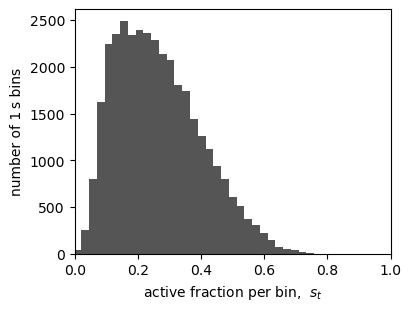

In [39]:
# ------------------------------------------------- (a) whole session
# s_t can only take multiples of 1/N, so bin edges are aligned to that
# grid: unaligned edges alternately capture one or two attainable values
# and produce a comb.
NKEEP  = Xk.shape[1]
bins_a = (np.arange(-0.5, NKEEP + 1.5, 3)) / NKEEP
fig, ax = plt.subplots(figsize=(4.0, 3.0), constrained_layout=True)
ax.hist(s_t, bins=bins_a, color="#555555")
ax.set_xlabel("active fraction per bin,  $s_t$")
ax.set_ylabel("number of 1\u2009s bins")
ax.set_xlim(0, 1)
fig.savefig(os.path.join(FIG_DIR, "fig3b_sparseness_hist.png"), dpi=300)
print("bins", len(s_t), "| mean", round(float(s_t.mean()), 3),
      "| median", round(float(np.median(s_t)), 3),
      "| 5-95%", np.round(np.percentile(s_t, [5, 95]), 3))


       mean     sd     bins
Wake  0.253  0.107   5698.0
NREM  0.304  0.145  15488.0
REM   0.223  0.085   2653.0


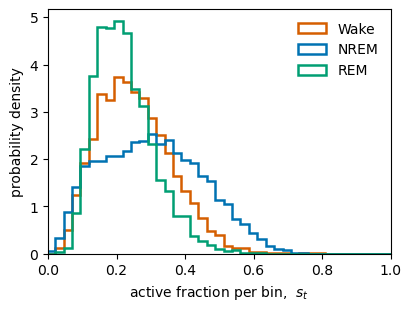

In [40]:
# --------------------------------------------------- (b) by state
# Density, not counts: NREM has six times REM's bins and would otherwise
# dominate the axis.
fig, ax = plt.subplots(figsize=(4.0, 3.0), constrained_layout=True)
for s in STATES:
    ax.hist(s_t[masks[s]], bins=bins_a, density=True, histtype="step",
            lw=1.8, color=COLORS[s], label=s)
ax.set_xlabel("active fraction per bin,  $s_t$")
ax.set_ylabel("probability density")
ax.set_xlim(0, 1)
ax.legend(frameon=False)
fig.savefig(os.path.join(FIG_DIR, "fig3c_sparseness_by_state.png"), dpi=300)
print(pd.DataFrame({s: dict(mean=s_t[masks[s]].mean(), sd=s_t[masks[s]].std(),
                            bins=int(masks[s].sum())) for s in STATES}).T.round(3).to_string())


## Public-databank sessions (DANDI mirror)

29 sleep-scored sessions streamed from dandisets 000044 (Grosmark, CA1, 8 sessions)
and 000041 (Watson, frontal cortex, 21 sessions). Only unit spike times, region
labels and the `behavior/states` intervals were read — no raw traces. The cell
below loads the 1 s binned matrices saved as `dandi_binned_1s.npz`; tonic units
(> 4.71 Hz) are already excluded, so every column is a retained unit.


In [52]:
# load the DANDI session cache
from pathlib import Path
from utils.population_metrics import compute_pca, compute_sparseness

DANDI_NPZ = Path('../data/dandi_binned_1s.npz')   # artifact from the crawl
N_SUB, FIT_RANGE, N_DRAWS, SEED = 25, (3, 50), 20, 1

z = np.load(DANDI_NPZ)
sessions = sorted(k[3:] for k in z.files if k.startswith('X__'))
dandi = {s: dict(X=z[f'X__{s}'].astype(float), state=z[f'state__{s}'],
                 region='CA1' if 'CA1' in '|'.join(z[f'region__{s}']) else 'CTX')
         for s in sessions}
print(len(dandi), 'sessions |',
      {r: sum(v['region'] == r for v in dandi.values()) for r in ('CA1', 'CTX')})


29 sessions | {'CA1': 8, 'CTX': 21}


In [49]:
# one row per session: sparseness and the exponent
rng = np.random.default_rng(SEED)

# Matched populations hold only N_SUB = 25 components, so the PCs 3-50 range
# used for the full Achilles population cannot be read on them; the
# cross-session convention is PCs 3-20 (analysis_config.FIT_RANGE_MATCHED).
FIT_RANGE_MATCHED = (3, 20)

def alpha_matched(X, n_sub=N_SUB, draws=N_DRAWS):
    """Mean exponent over `draws` neuron subsamples, so every session is
    measured at the same neuron count, fitted over PCs 3-20."""
    vals = [compute_pca(X[:, rng.choice(X.shape[1], n_sub, replace=False)],
                        fit_range=FIT_RANGE_MATCHED)[1] for _ in range(draws)]
    return float(np.mean(vals)), float(np.std(vals))

rows = []
for s, d in dandi.items():
    if d['X'].shape[1] < N_SUB:
        continue                      # too few retained units to match
    a, sd = alpha_matched(d['X'])
    r = dict(session=s, region=d['region'], n_retained=d['X'].shape[1],
             s_mean=compute_sparseness(d['X'])[0].mean(), alpha=a, alpha_sd=sd)
    for st in ('Wake', 'NREM', 'REM'):
        m = d['state'] == st
        r[f's_{st}'] = compute_sparseness(d['X'][m])[0].mean() if m.sum() > 30 else np.nan
        r[f'alpha_{st}'] = alpha_matched(d['X'][m])[0] if m.sum() > 300 else np.nan
    rows.append(r)

dandi_tbl = pd.DataFrame(rows).round(4)
dandi_tbl.to_csv('alpha_by_session_state.csv', index=False)
print(dandi_tbl.groupby('region')[['s_mean', 'alpha']].mean().round(3))


        s_mean  alpha
region               
CA1      0.299  1.546
CTX      0.383  1.789


In [ ]:
# ------------------------------------------- (e) co-activation by state
# Mean Pearson correlation between the BINARISED spike trains of the 122
# retained neurons, over all pairs, computed separately within each state.
# Binarised rather than spike counts because s_t and a_i are defined on the
# same binary matrix, so the correlation, the recruitment variance and the
# identity linking them all refer to one quantity. (The spike-count version,
# plotted in earlier drafts, is printed below for reference.)
iu = np.triu_indices(Xk.shape[1], 1)
rows = []
for st in STATES:
    m = masks[st]
    B = (Xk[m] > 0).astype(float)
    rows.append(dict(state=st, bins=int(m.sum()), n_pairs=len(iu[0]),
                     r_binarised=float(np.nanmean(np.corrcoef(B.T)[iu])),
                     r_counts=float(np.nanmean(np.corrcoef(Xk[m].astype(float).T)[iu])),
                     median_r=float(np.nanmedian(np.corrcoef(B.T)[iu])),
                     frac_above_0p1=float(np.mean(np.corrcoef(B.T)[iu] > .1))))
coact = pd.DataFrame(rows).set_index("state")

fig, ax = plt.subplots(figsize=(3.8, 3.6), constrained_layout=True)
for i, st in enumerate(STATES):
    ax.bar(i, coact.r_binarised[st], width=.62, color=COLORS[st])
    ax.annotate(f"{coact.r_binarised[st]:.3f}", (i, coact.r_binarised[st]),
                textcoords="offset points", xytext=(0, 3), ha="center",
                fontsize=7.5, color=COLORS[st])
ax.set_xticks(range(len(STATES))); ax.set_xticklabels(STATES)
ax.set_ylabel("mean pairwise correlation $r$")
ax.set_ylim(0, max(coact.r_binarised) * 1.22)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "fig3e_coordination_by_state.png"), dpi=300)

coact.round(4).to_csv("fig3e_coactivation.csv")
print(coact.round(4).to_string())


In [ ]:
# ---- control: is co-activation an artefact of pooling across episodes?
# Each state is dozens of separate bouts spread over hours. A shared slow drift
# between bouts would inflate every pair's correlation without any real
# second-to-second coupling. Removing it by centring each neuron within each bout.
def _bouts(mask, min_bins=10):
    d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return [(a, b) for a, b in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1))
            if b - a >= min_bins]

_B = (Xk > 0).astype(float)
_iu = np.triu_indices(Xk.shape[1], 1)
rows = []
for s in STATES:
    m = masks[s]
    pooled = float(np.nanmean(np.corrcoef(_B[m].T)[_iu]))
    bb = _bouts(m)
    Z = np.concatenate([_B[a:b] - _B[a:b].mean(0) for a, b in bb])
    within = float(np.nanmean(np.corrcoef(Z.T)[_iu]))
    rows.append(dict(state=s, n_bouts=len(bb), r_pooled=pooled, r_within_bout=within,
                     difference=pooled - within, pct_of_pooled=100 * (pooled - within) / pooled))
WB = pd.DataFrame(rows).round(4)
WB.to_csv("coactivation_within_bout.csv", index=False)
print(WB.to_string(index=False))
